In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import datetime as dt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,SimpleRNN,Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

import warnings
warnings.filterwarnings('ignore')

import os 
os.environ["TF_CPP_MIN_LOG_LEVEL"] = '3'
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)

In [5]:
df = pd.read_csv("international-airline-passengers.csv")

In [6]:
df.columns

Index(['Month', 'International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60'], dtype='str')

In [7]:
df.columns = ["Month", "Passenger"]

In [8]:
df.head()

,Month,Passenger
0,1949-01,112.0
1,1949-02,118.0
2,1949-03,132.0
3,1949-04,129.0
4,1949-05,121.0


In [12]:
df.tail()

,Month,Passenger
140,1960-09,508.0
141,1960-10,461.0
142,1960-11,390.0
143,1960-12,432.0
144,International airline passengers: monthly tota...,NaN


In [9]:
df.shape

(145, 2)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Month      145 non-null    str    
 1   Passenger  144 non-null    float64
dtypes: float64(1), str(1)
memory usage: 2.4 KB


In [11]:
df.describe()

,Passenger
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


In [16]:
df = df[:144]

In [17]:
df.tail()

,Month,Passenger
139,1960-08,606.0
140,1960-09,508.0
141,1960-10,461.0
142,1960-11,390.0
143,1960-12,432.0


In [18]:
df["Month"] = pd.to_datetime(df["Month"])

In [19]:
df.index = df["Month"]

In [20]:
df.head()

,Month,Passenger
Month,,
1949-01-01,1949-01-01,112.0
1949-02-01,1949-02-01,118.0
1949-03-01,1949-03-01,132.0
1949-04-01,1949-04-01,129.0
1949-05-01,1949-05-01,121.0


In [22]:
df.drop("Month",axis=1,inplace=True)

In [23]:
result_df = df.copy()

<Axes: title={'center': 'Monthly airline passengers'}, xlabel='Month'>

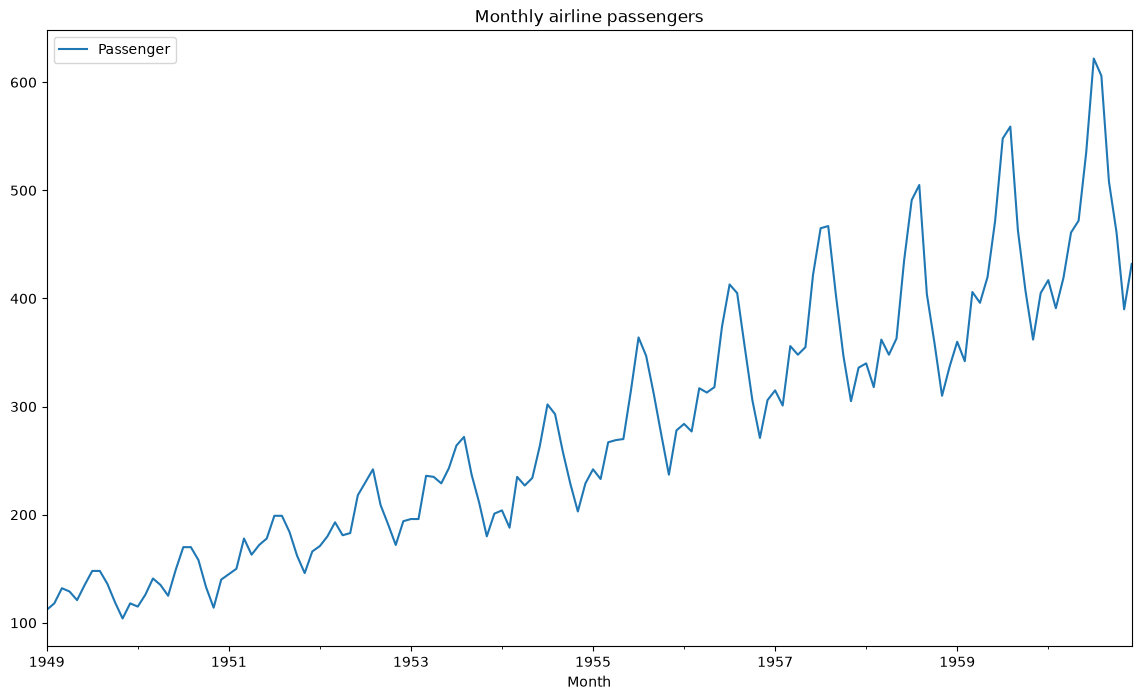

In [24]:
df.plot(figsize=(14,8), title="Monthly airline passengers")

In [29]:
data = df["Passenger"].values

In [30]:
data[0:5]

array([112., 118., 132., 129., 121.])

In [32]:
data = data.astype('float32')

In [33]:
data.shape

(144,)

In [36]:
def split_data(dataframe,test_size):
    position = int(round(len(dataframe) * (1-test_size)))
    train = dataframe[:position]
    test = dataframe[:position]
    return train,test,position

In [37]:
train,test,position = split_data(data,0.33)

In [38]:
scaler_train = MinMaxScaler(feature_range=(0,1))

In [40]:
train = pd.DataFrame(train)

In [41]:
train = scaler_train.fit_transform(train)

In [42]:
scaler_test = MinMaxScaler(feature_range=(0,1))

In [43]:
test = pd.DataFrame(test)

In [45]:
test = scaler_test.fit_transform(test)

In [46]:
def create_features(data,lookback):
    X,y = [],[]
    for i in range(lookback,len(data)):
        X.append(data[i-lookback:i,0])
        y.append(data[i,0])

    return np.array(X), np.array(y)

In [47]:
lookback = 1

In [48]:
X_train,y_train = create_features(train,lookback)

In [49]:
X_test, y_test = create_features(test,lookback)

In [50]:
model = Sequential()

model.add(SimpleRNN(units=50,activation='relu',input_shape=(X_train.shape[1],lookback)))

In [51]:
model.add(Dropout(0.2))

In [52]:
model.add(Dense(1))

In [54]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 50)                  │           2,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
model.compile(loss="mean_squared_error", optimizer='adam',)

In [56]:
callbacks = [EarlyStopping(monitor="val_los",patience=3,verbose=1,mode='min'),
            ModelCheckpoint(filepath='mymodel.keras',monitor='val_los',mode='min',save_best_only=True,save_weights_only=False,verbose=1)]

In [57]:
history = model.fit(x=X_train,y=y_train,epochs=50,batch_size=1,validation_data=(X_test,y_test),callbacks=callbacks,shuffle=False)

Epoch 1/50
93/95 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0133
Epoch 1: finished saving model to mymodel.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - loss: 0.0134 - val_loss: 0.0271
Epoch 2/50
87/95 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0191
Epoch 2: finished saving model to mymodel.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0182 - val_loss: 0.0149
Epoch 3/50
89/95 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0124
Epoch 3: finished saving model to mymodel.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0132 - val_loss: 0.0100
Epoch 4/50
88/95 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0098
Epoch 4: finished saving model to mymodel.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0112 - val_loss: 0.0069
Epoch 5/50
86/95 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0094
Epoch 5: finished saving model to mymodel.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0103 - val_loss: 0.0067
Epoch 6/50
86/95 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0069


ValueError: 'upper_right' is not a valid value for loc. Did you mean one of: 'upper right', 'lower right', 'right'?

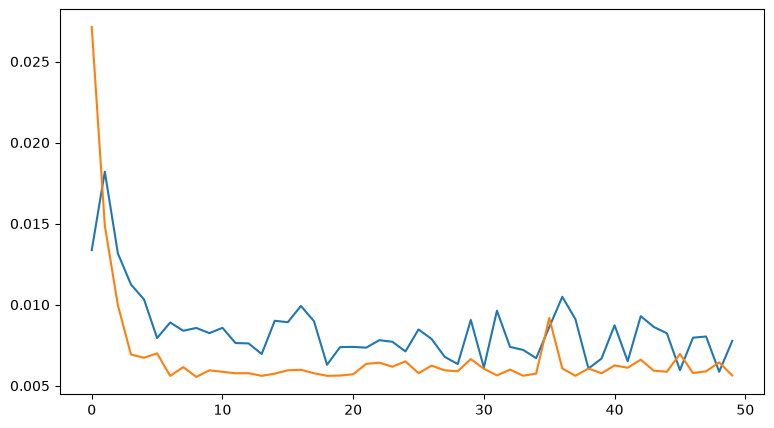

In [58]:
plt.figure(figsize=(20,5))
plt.subplot(1,2,2)
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend(loc='upper_right')
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Loss', fontsize=16)
plt.ylim([0,max(plt.ylim())])
plt.title('Training and Validation LOss graphs', fontsize=16)
plt.show()

In [59]:
loss = model.evaluate(X_test,y_test, batch_size=1)
print("Test loss: %.1f%%" % (100.0 * loss))

95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0056
Test loss: 0.6%


In [60]:
train_predict = model.predict(X_train)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 278ms/step


In [61]:
test_predict = model.predict(X_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step


In [62]:
train_predict = scaler_train.inverse_transform(train_predict)
test_predict = scaler_test.inverse_transform(test_predict)

In [63]:
train_rmse = np.sqrt(mean_squared_error(y_train,train_predict))
test_rmse = np.sqrt(mean_squared_error(y_test,test_predict))

In [64]:
print(f"Train RMSE: {train_rmse}")
print(f"Test RMSE: {test_rmse}")

Train RMSE: 224.79118782772602
Test RMSE: 224.79118782772602


In [65]:
df.describe()

,Passenger
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


In [66]:
result_df

,Passenger
Month,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0
...,...
1960-08-01,606.0
1960-09-01,508.0
1960-10-01,461.0


In [67]:
train_predict_df = result_df[lookback:position]

In [68]:
train_predict_df["Prediction"] = train_predict

In [69]:
train_predict_df.head()

,Passenger,Prediction
Month,,
1949-02-01,118.0,136.162003
1949-03-01,132.0,136.511124
1949-04-01,129.0,140.804092
1949-05-01,121.0,139.090393
1949-06-01,135.0,136.685669


In [71]:
test_predict_df = result_df[position+lookback:]
test_predict_df["Prediction"] = test_predict
test_predict.head()

ValueError: Length of values (95) does not match length of index (47)